# Simon's algorithm on Qmio

*Hands-on session of the Jornada de Introducción a la Computación Cuántica (Quantum Spain, TalentQ and CESGA)*

14th April 2026

Authors:

* Irais Bautista (CESGA)
* Javier Mas (IGFAE-USC)
* Andrés Gómez (CESGA)


<a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img aling="left" alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a><br />License: <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons  4.0 International</a>.

$ \renewcommand{\bra}[1]{\langle #1|} $
$ \renewcommand{\ket}[1]{|#1\rangle} $
$ \renewcommand{\braket}[2]{\langle #1|#2\rangle} $

<div class="alert alert-block alert-warning">

<center><u>Welcome to the <b>Hands On</b> session of the <b>I International Masterclass in Quantum Computing</b></u></center>


In this notebook, we will experiment with the resources of quantum computing:
- *superposition*
- *parallelism*
- *interference*
- *entanglement*
<br>
    
Our <u>target</u> will be to perform the **Simon's algorithm**: the first quantum algorithm exhibiting **exponential speedup** over it's classical counterpart.
    
We will mostly <u>emulate</u> the quantum circuits, but ocasionally you will be able to <u>send it to a real quantum computer</u>, so as to grasp the state of this incipient technology. 
    
</div>

###  - Coding in [Qibo](https://qibo.science/) -

The present notebook uses Qibo, an <u>open-source framework</u> for quantum computing which is pushed by an international collaboration including CERN. It is designed with a focus on hardware independence and high-performance simulation.

### - Running on [Qmio>](https://quantum.cesga.es/infraestructures/)  -

To run this notebook you will make use of the <b>Qmio></b> infrastructure, a [<u>quantum computer</u>](https://quantum.cesga.es/infraestructures/) located at CESGA (Centro de Supercomputación de Galicia) based on superconducting qubits.
    
You will have  <u>two options</u>:

-  $\Rightarrow$ <b>FakeQmio</b> is a <u>simulator of the Qmio hardware</u>. It includes  noise models and specifications like real time  qubit calibrations. <br>
Sending to FakeQmio has almost no queue delay. So you should <u>use this option by default</u>.<br>
To run this option set <i>'run_hardware = False'</i>.  
<br>

-  $\Rightarrow$ <b>Qmio</b> This is the <u>real QPU hardware</u>. It is a NISQ computer, so results are noisy and inaccurate.  <br>
Sending to Qmio puts you in a queue. If you get stuck,  you must <u>restart the notebook</u>. So use this option with care. <br>
To run this option set <i>'run_hardware = True'</i>. 



<a id='top'></a>

### Contents:

- [I Superposition](#superposition) 


- [II Parallelism](#parallelism)


- [III Interference](#interference)




- [IV Simon's algorithm](#simons)
    

In [1]:
import sys, os

sys.path.append(os.path.abspath("macros"))

from macro_tQ import *
%matplotlib inline

<a id='superposition'></a>
#  I. Superposition
[<<<](#top)

<div class="alert alert-block alert-info">

- The **state of a bit** can only be 0 or 1.
<br>

- The **state of a qubit** can be a linear superposition $\ket{\psi} = a\ket{0} + b\ket{1}$ where  $|a|² + |b|² = 1$. 

</div>


## Summary of quantum states and measurements


The initial state in a quantum circuit is  $\ket{0}$,  the lowest energy eigenstate

- From this, we can prepare any state by applying quantum gates.

$$
\ket{0} ~~~\stackrel{\hbox{gates}}{\longrightarrow}~~~ \ket{\psi} = a \ket{0} + b \ket{1} ~~~~~\hbox{with}~~ |a|^2 + |b|^2 = 1
$$
<br>

- Everytime we  <b>measure</b>, the state collapses to either $\ket{0}$ or $\ket{1}$
$$
\ket{\psi} = a \ket{0} + b \ket{1} ~~~ \longrightarrow~~~
\left\{ \begin{array}{cc}\hbox{collapses to } & \hbox{measures} \\ \ket{0} & 0 \\ \ket{1} &   1 \end{array} \right.
$$
<br>


- The probabilities of either case, $p(0)$ and $p(1)$, are approximated by  the <b>relative frequencies</b> of appearance of $0$ or $1$ for large number $N$ of measurements 


$$
p(0) = |a|^2 \approx \frac{n(0)}{N} ~~~~~~,~~~~~~~ p(1) = |b|^2 \approx \frac{n(1)}{N}
$$
    


### One-qubit circuits

To prepare a state we use **gates** to compose **circuits**

-  $X$ gate is the quantum analog of the classical NOT

$$
X \ket{0} = \ket{1} ~~~~~~~~~~; ~~~~~~~~~ X \ket{1} = \ket{0}
$$

- $Z$ gate flips the sign of $\ket{1}$, (has no classical analog, since no bit can take value  -1)

$$
Z \ket{0} = \ket{0}~~~~~~~~~~; ~~~~~~~~~~Z\ket{1} = -\ket{1}~~~
$$

-  $H$  (or *Hadamard*) gate, creates  *balanced superpositions* of $\ket{0}$ and $\ket{1}$. 
<br>

$$
H \ket{0}  =\frac{1}{\sqrt{2}} \big( \ket{0} + \ket{1}\big) = \ket{+} ~~~~~~~; ~~~~~~~ H\ket{1} = \ket{-} =\frac{1}{\sqrt{2}} \big( \ket{0} - \ket{1}\big)= \ket{-}
$$
<br>


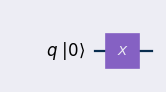

In [2]:
c = Circuit(1)
# uncomment to create generic states 
c.add(gates.X(0))
# c.add(gates.H(0))
# c.add(gates.Z(0))
# c.add(gates.RY(0, np.pi/4))

draw_qibo(c,scale=0.8);


We can visualize the final state in <u>three different ways</u>:

 $(a)~$ By <u>expanding in the **basis**</u> $\ket{0}, \ket{1}$

In [3]:
show_state(c)

<IPython.core.display.Latex object>

$(b)~$ By <u>drawing</u> on the **Bloch sphere**

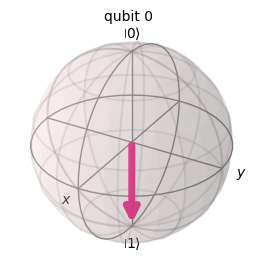

In [4]:
show_bloch(c);

$(c)$ By <u>making measurements</u> to obtain **output frequencies**


For this we need to <i>add measurements<i> to the circuit

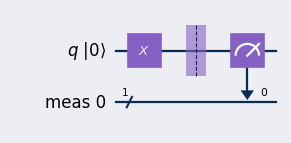

In [5]:
# we add measurements in a copy of the circuit
c_measure = c.copy()
c_measure.add(gates.M(0))

# draw the circuit with a scale
draw_qibo(c_measure,scale=0.8);

We repeat the measurement a number of times  "shots". This allows to recover probabilities

<div class="alert alert-block alert-warning">
<b> Remember:</b>
    
Setting 'run_hardware=False' only simulates in **FakeQmio**. 
<br>
Setting 'run_hardware=True'  simulates in **FakeQmio** and runs in **Qmio**. It may get stuck in the queue.

<div>

In [6]:
from common_config import QMIO_RESERVATION
print("QMIO_RESERVATION =", QMIO_RESERVATION)

QMIO_RESERVATION = None


In [7]:
shots = 100

run_hardware = True

counts = run_qmio(circuit_to_qmio(c_measure), shots=shots, run_hardware=run_hardware)

Fake QMIO: {'1': 100}
QMIO job_id: af505494-140f-46e1-a6bb-9fe36c18f5ed
QMIO: {'1': 85, '0': 15}


The results are given as dictionaries

In [8]:
print('counts FakeQmio=', counts["fake_qmio"])

if run_hardware == True:
    print('counts Qmio=', counts["qmio"])

counts FakeQmio= {'1': 100}
counts Qmio= {'1': 81, '0': 19}


We use histograms to visualize the results better

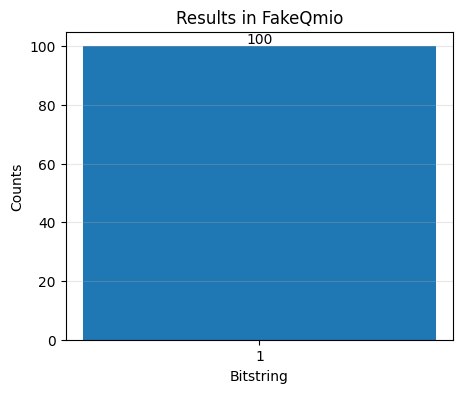

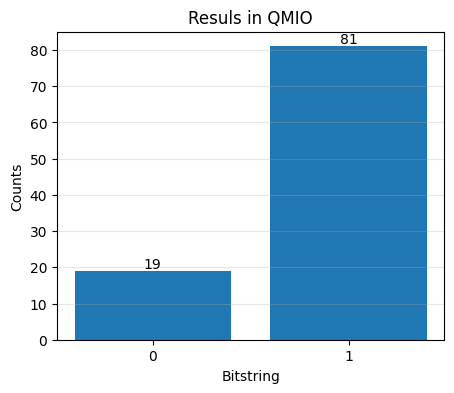

In [9]:
plot_counts(counts["fake_qmio"], figsize=(5, 4), title="Results in FakeQmio")

if run_hardware == True:
    plot_counts(counts["qmio"], figsize=(5, 4), title="Resuls in QMIO")

- The **probabilities** $p(0)$ and $p(1)$ are approximated by  the relative frequencies

$$p(0) = |a|^2 = \frac{n(0)}{N} ~~~~~~~\hbox{y} ~~~~~~~~~ p(1) = |b|^2 = \frac{n(1)}{N}$$

In [10]:
def probabilities(counts, N = shots):
    return {bitstring : n/N for  bitstring, n in counts.items()}

probabilities(counts["fake_qmio"], shots)

{'1': 1.0}

<div class="alert alert-block alert-success">
<b>Go play!</b> 
    
Modify the circuit by uncommenting one or various lines. 
    
- Observe the resulting circuit and states. 
<br>
    
- Obtain the probabilities and verify that  $p(0)= |a|^2$ and $p(1) = |b|^2$    
<br>
    
- Change '<i>run_hardware</i> = True' and observe the presence of noise.
    
</div>


## Multiqubit circuits 

Consider an arbitrary <u>two-qubit</u> state:

$$
\ket{\psi}_1 \ket{\psi}_2  ~=~ \big(a_1 \ket{0} + b_1\ket{1}\big) \big( a_2\ket{0} + b_2\ket{1}\big) ~=~
a_1a_2 \ket{00} + a_1 b_2 \ket{01} + a_2 b_1 \ket{10} + a_2 b_2 \ket{11}
$$

We say that the states $\{ \ket{00},\ket{01},\ket{10},\ket{11} \}$ form a **basis** of the **two-qubit space**.

<br>

- By measuring both qubits, 
$$
\ket{\psi}_1\ket{\psi}_2 \longrightarrow \left\{
\begin{array}{ccc}
\hbox{the state collapses to } & \hbox{with probability} & \hbox{obtaining measurement} \\
\ket{00} & |a_1a_2|^2 & 00 \\
\ket{01} & |a_1b_2|^2 & 01\\
\ket{10} & |b_2a_1|^2 & 10\\
\ket{11} & |b_2b_2|^2 & 11\\
\end{array}
\right.
$$
<br>


<div class="alert alert-block alert-warning">
<i>You can easily prove that the sum of all these numbers equals 1. That is, they are probabilities.</i>
</div>

We will generate possible states using 1-qubit gates inserted into each register of the circuit

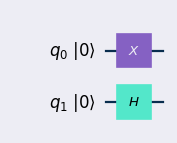

In [11]:
n = 2

c = Circuit(n)
c.add(gates.X(0))
c.add(gates.H(1))
#c.add(gates.Y(0))
#c.add(gates.Z(1))
#c.add(gates.RY(0, np.pi / 4))

draw_qibo(c,scale=0.8);


We write the resulting state in the *2-qubit basis*

In [12]:
show_state(c)

<IPython.core.display.Latex object>

or on the Bloch sphere

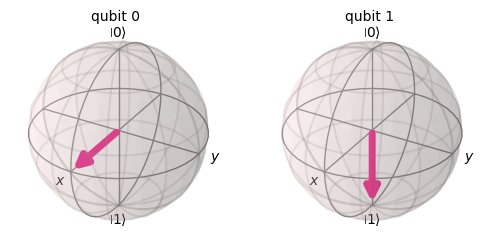

In [13]:
show_bloch(c);

Or by making measurements

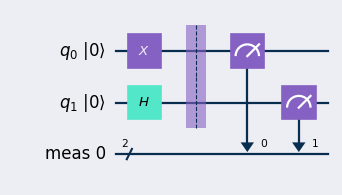

In [14]:
c_measure = c.copy()
c_measure.add(gates.M(*range(n)))

draw_qibo(c_measure,scale=0.8);

In [19]:
shots = 1000

run_hardware=True

counts = run_qmio(circuit_to_qmio(c_measure), shots=shots, run_hardware=run_hardware)

Fake QMIO: {'10': 1, '00': 1, '11': 488, '01': 510}
QMIO job_id: 4de17b51-735b-429c-b7fb-2e8f632d1460
QMIO: {'01': 474, '11': 393, '10': 43, '00': 90}


Print results from emulating in *FakeQmio*

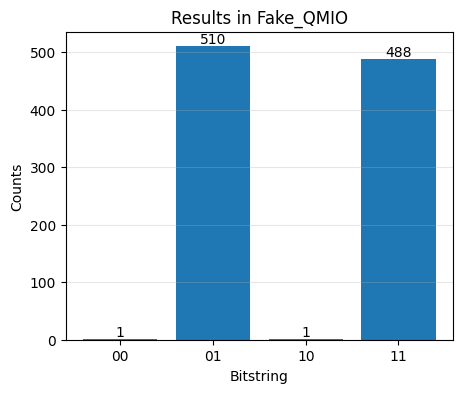

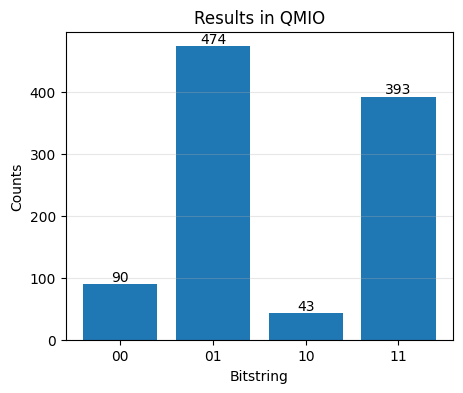

In [20]:
plot_counts(counts["fake_qmio"], figsize=(5, 4), title="Results in Fake_QMIO")

if run_hardware:
    plot_counts(counts["qmio"], figsize=(5, 4), title="Results in QMIO")

<div class="alert alert-block alert-success">
<b>Go play!</b>
    
 Modify the circuit by changing the gates and observe the statistics. 
    
 Compare the  simulated result (FakeQmio) with the real one (Qmio) as you add more gates.

</div>

<a id='parallelism'></a>
# II  Parallelism
[<<<](#top)

<img src="https://media0.giphy.com/media/v1.Y2lkPTc5MGI3NjExMjF0d3MxMG95bHoybDRvcGxhcjZ3eDV1emxkeG5oOWxxa2JoYmRnbSZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/iN3CJyETisdv1gVbdY/giphy.gif" width="300">




### The Walsh-Hadamard gate

Many algorithms begin with this <u>important</u> $n$-qubit gate: the  **Walsh-Hadamard** gate, 

$H^n$  applies the $H$ gate to **all** the qubits in the $\ket{0}...\ket{0}= \ket{0...0} = \ket{0}_n$ state.

For example, with $n=2$
\begin{align}
H^2\ket{00} = H\ket{0} H\ket{0} &= \ket{+}\ket{+}  \rule{0mm}{9mm}\\
& = \frac{1}{\sqrt{2}}(\ket{0} + \ket{1})\frac{1}{\sqrt{2}}(\ket{0} + \ket{1})\nonumber\\
& = \frac{1}{2}\Big( \ket{00}  + \ket{01} +\ket{10}+ \ket{11} \Big)
\end{align}

The resulting state is always an **even superposition** of **all** the <u>basis state</u>.


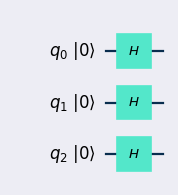

In [21]:
n = 3

c = Circuit(n)

for q in range(n):
    c.add(gates.H(q))

draw_qibo(c,scale=0.8);

Visualize the state in the computational basis

In [22]:
show_state(c);

<IPython.core.display.Latex object>

or on the Bloch sphere

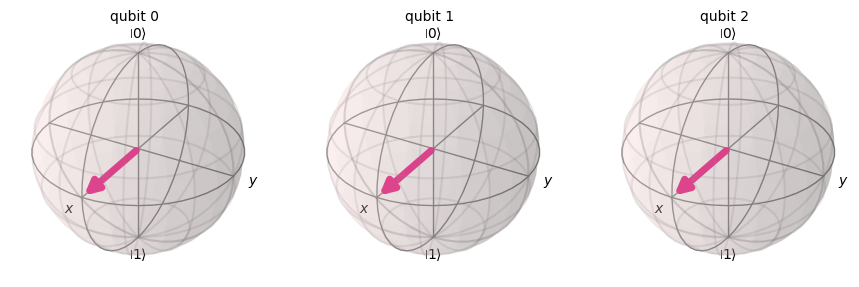

In [23]:
show_bloch(c);

or by measuring the outcomes of running the circuit

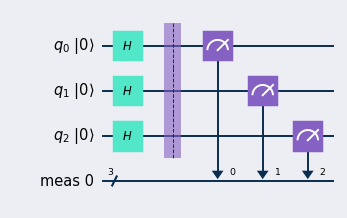

In [24]:
c_measure = c.copy()
c_measure.add(gates.M(*range(n)))

draw_qibo(c_measure,scale=0.7);

In [25]:
shots = 1000 

run_hardware = True

counts = run_qmio(circuit_to_qmio(c_measure), shots=shots, run_hardware=run_hardware)

Fake QMIO: {'110': 137, '101': 125, '000': 103, '010': 111, '001': 123, '111': 131, '011': 139, '100': 131}
QMIO job_id: 985ae064-3531-4778-829b-69fcd6e55f58
QMIO: {'110': 54, '111': 104, '010': 55, '100': 169, '000': 177, '101': 169, '011': 136, '001': 136}


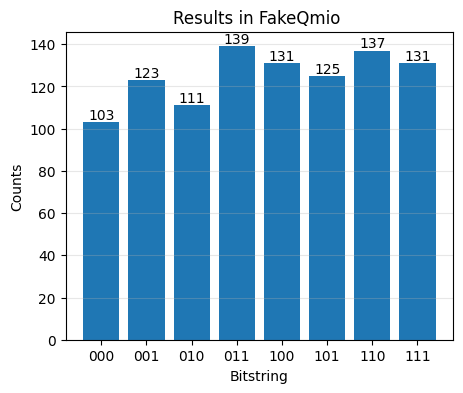

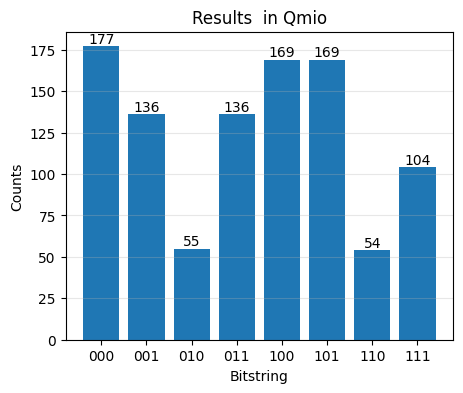

In [26]:
plot_counts(counts["fake_qmio"], figsize=(5, 4), title="Results in FakeQmio ")

if run_hardware:
    plot_counts(counts["qmio"], figsize=(5, 4), title="Results  in Qmio")

<div class="alert alert-block alert-success">
<b>Go play!</b>
    
- run the previous cells with a higher value of $n$.

- run the previous cells with a higher value of $shots$.
    
- try inserting a single X gate before the Walsh-Hadamard gate.  
    
</div>

<div class="alert alert-block alert-warning">

### Summary: parallelism in action!    
    
In a <u>classical computer</u>, the above operation would require:


- *modifying*  $2^n$    registers  requires $2^n$ **steps** $\Rightarrow$ this task  is  <b>exponentially complex</b>. 
 

In a <u>quantum computer</u>, parallelism is native:


- *modifying* **all** the $2^n$ amplitudes is <u>performed simultaneously</u> in **one single step**. 
   
- adding a single $X$ gate changes many signs simultaneously.
    
</div>

<a id='interference'></a>
# III. Interference
[<<<](#top)

<img src="https://media1.giphy.com/media/v1.Y2lkPTc5MGI3NjExNHg2NWM3dGlnNWNubGRnOHhicWNzMXpidm5xMHh4em1zaTRlNmJwaiZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/ybR0YqgiZFVVJWvZOe/giphy.gif" width="200">



<div class="alert alert-block alert-info">
    
-  <b>Probabilities</b> like $p(0) = |a|^2$ and $p(1) = |b|^2$ are <u>always positive</u> numbers. It is impossible for a sum of probabilities to be zero.
<br>
    
-   **Probability amplitudes**, $a$ and $b$, are complex numbers. Therefore, it is possible to obtain a result with zero amplitude, $a + b = 0$, even though all the contributing amplitudes are not zero. This is the phenomenon of interference.

</div>

## Example:  the Quantum Coin


-  A <u>coin</u> is a paradigmatic <i>probabilistic</i> system where 2 results -*Heads* or *Tails*- can happend with equal <b>probability</b> $H\to 1/2 ,T \to 1/2$


 - <u>Acting with the Hadamard gate</u>, $H$, is the <i>quantum analogue</i> of <u>tossing a coin</u>. 
 <br>
 $$
 H \ket{0} = \frac{1}{\sqrt{2}} \big(\ket{0} + \ket{1}\big) ~~~~~~;~~~~~
~~  H \ket{0} = \frac{1}{\sqrt{2}} \big(\ket{0} - \ket{1}\big)
 $$
<br> 
 
 - When we measure it, the result is always either $\ket{0} \sim \hbox{Head}$ or $\ket{1} \sim \hbox{Tail}$ with probabilities $\big(1/\sqrt{2}\big)^2 = 1/2$ each.
<br>

### Quantum coin tossing circuit 

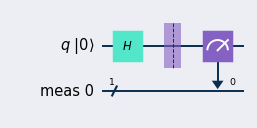

In [27]:
n = 1  #number of coins
c_coin = Circuit(n)

for i in range(n):
    c_coin.add(gates.H(i))     
#    c_coin.add(gates.M(i))
#    c_coin.add(gates.H(i))  

c_coin.add(gates.M(*range(n)))

draw_qibo(c_coin,scale=0.7);

In [28]:
shots = 1000

run_hardware = True
counts_a = run_qmio(circuit_to_qmio(c_coin), shots=shots, run_hardware=run_hardware)


Fake QMIO: {'1': 490, '0': 510}
QMIO job_id: 97796fd6-dbc3-444a-bffb-c41f870ce4be
QMIO: {'0': 520, '1': 480}


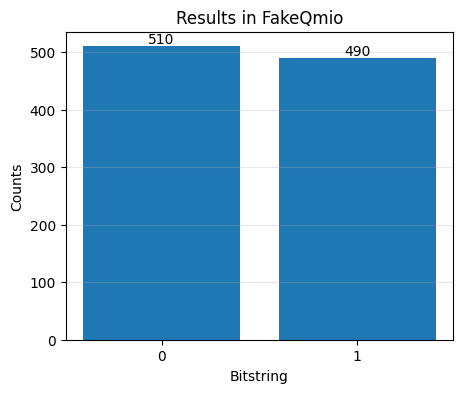

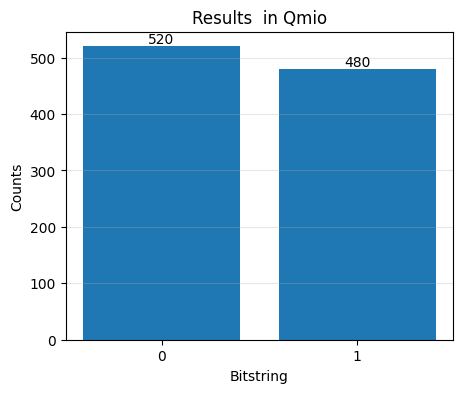

In [29]:
plot_counts(counts_a["fake_qmio"], figsize=(5, 4), title="Results in FakeQmio")

if run_hardware:
    plot_counts(counts_a["qmio"], figsize=(5, 4), title="Results  in Qmio")

This is the expected result, like a normal classical coin.

<div class="alert alert-block alert-success"

<b> Go play! </b> (*set run_hardware=False*)


- Add a **second coin tossing** in the circuit and observe the result. Is this behaving like a classical coin?

- Add a **additional coin tossings** in the circuit and observe the result. Is this behaving like a classical coin?

- Interleave **measurement** in between the Hadamard gates and see when the interference is destroyed. 

- Set $n=3,4,..$ and <u>observe **how brutal**  is the interference effect</u> by adding several Walsh-Hadamard layers
</div>


### The interference effect in the Quantum Coin 

**Tossing once** a quantum coin which is initially in $\ket{0}$ (Heads) or $\ket{1}$ (Tails)   means

$$
H : \ket{0} \to \frac{1}{\sqrt{2}}\Big( |0\rangle +|1\rangle \Big)  = \ket{+} 
~~~~~~~~~;~~~~~~~~~~~
H : \ket{1} \to \frac{1}{\sqrt{2}}\Big( |0\rangle -|1\rangle \Big)  = \ket{+}
$$

In either case, the probabilities of collapsing to $\ket{0}$ (heads) or $\ket{1}$ (tails) upon measurement   is the same (as for a classical coin):

$$
p(0) = \left\vert \frac{1}{\sqrt{2}}\right\vert^2 = 0.5~~~~~~~~;~~~~~~~~ p(1) = \left\vert \pm\frac{1}{\sqrt{2}}\right\vert^2 = 0.5
$$



**Tossing twice** a quantum coin **without measuring** in between means (if initially in $\ket{0}$)

\begin{align}
\ket{0}~~\stackrel{\hbox{two tosses}}{\longrightarrow}~~ H^2\ket{0}  ~~ = ~~ H\frac{1}{\sqrt{2}}\Big(|0\rangle + |1\rangle \Big)  =  \frac{1}{\sqrt{2}}\Big(H|0\rangle + H|1\rangle \Big) ~~ = & ~~~
 \frac{1}{\sqrt{2}} 
\left( \frac{1}{\sqrt{2}}\big(|0\rangle + |1\rangle \big) + \frac{1}{\sqrt{2}}\big(|0\rangle - |1\rangle \big) \right)\nonumber \\
& =\left( \frac{1}{2}+\frac{1}{2}\right) \ket{0} + \left( \frac{1}{2}-\frac{1}{2}\right) \ket{1} \rule{0mm}{8mm} \nonumber \\
& = \ket{0}  \rule{0mm}{8mm} \nonumber
\end{align} 

or, if initially in $\ket{1}$

\begin{align}
\ket{1} ~~\stackrel{\hbox{dos tiradas}}{\longrightarrow} ~~H^2\ket{1}  ~~ =  ~~ H\frac{1}{\sqrt{2}}\Big(|0\rangle - |1\rangle \Big)  =  \frac{1}{\sqrt{2}}\Big(H|0\rangle - H|1\rangle \Big) ~~ = & ~~~
 \frac{1}{\sqrt{2}}
\left( \frac{1}{\sqrt{2}}\big(|0\rangle + |1\rangle \big) - \frac{1}{\sqrt{2}}\big(|0\rangle - |1\rangle \big) \right) \nonumber \\
& =\left( \frac{1}{2}-\frac{1}{2}\right) \ket{0} + \left( \frac{1}{2}+\frac{1}{2}\right) \ket{1} \rule{0mm}{8mm} \nonumber\\
& = \ket{1}  \rule{0mm}{8mm} \nonumber
\end{align} 


We clearly observe the **interference** produced upon composing amplitudes instead of probabilities

- **constructive** to obtain the *intial state* again with *probability one*
<br>

- **destructive** to obtain the *opposite state*  with *probability zero*



<a id='simons'></a>
# IV. Simon's algorithm  
[<<<](#top)

<br>

</div>
*[Image of the original material: not included]*

In 1994 David Simon published the first quantum algorithm that exhibited <b>exponential speedup</b> over its classical counterpart. It is not a deterministic algorithm, meaning that the correct answer is obtained, but only with a high probability. 


### Some definitions.

- **Bitstring set:** $S_n$  denotes the set of **all** $n$-bitstrings. For example:  

$$S_3 =  \{ 000,001,010,011,100,101,110,111\}. $$

- **Bitwise addition:** Given *two bitstrings* $x,y\in S_n, ~\to ~x\oplus y~$ denotes *bitwise addition modulo two*. For example: 

$$  x \oplus y = 110 \oplus 100 = 010 $$

## Functions

An <u>$n-$digital function</u> is a map $f : S_n \to S_n$ that associates, to each $x\in S_n$ an image $f(x)\in S_n$. 


To specify such an $f : S_n \to S_n$ it is enough to <u>provide a dictionary</u> of $2^n$ outputs $f(x)$, of $2^n$ bits each.




In [30]:
# Example 1, n=3
f_3 = {'000':'111', '110':'111', '001':'100', '111':'100', '010':'011', '100':'011', '011':'000', '101':'000'}

# Example 2, n=4
f_4 = {'0000': '1001', '0001': '1101', '0010': '0001', '0011': '0101', '0100': '0001', '0101': '0101', 
       '0110': '1001', '0111': '1101', '1000': '1010', '1001': '1110', '1010': '0010', '1011': '0110', 
       '1100': '0010', '1101': '0110', '1110': '1010', '1111': '1110'}


You can always **call the function** and evaluate it on a given argument


In [31]:
### change the value of this bitstring
x = '011'
print('f_3(',x,')=',f_3[x])

f_3( 011 )= 000


We can evaluate **all** the arguments and list them in a table

In [32]:
display_latex_table(f_3)

<IPython.core.display.Latex object>

The list grows exponentially as $2^n$ hence we cannot do this except for small $n=2,3,4$. 


### Periodic functions 

<div class="alert alert-block alert-info">
We say that an $n$-digital function  $f: S_n \to S_n$ is  <b>periodic</b> with <u>period</u> $s\in S_n$ if 

$$
 f(x) = f(x\oplus s) ~~~~~
$$
</div>

<div class="alert alert-block alert-warning">
<b> Notice:</b>   the previous functions $f_3$ and $f_4$ <u>do have a period</u> $s$ 

- Could you find $s$ by inspection?
<br>
    
- How many values of $f(x)$ did you need to inspect to find $s$?


</div>

Here is a code that generates for you a **random periodic $n$-digital function**  once you specify $s$

In [33]:
s = '1101'
f = build_periodic_function(s)
display_latex_table(f)

<IPython.core.display.Latex object>

<div class="alert alert-block alert-success">
<b> Check out! </b>
 that $s$ is indeed the periodicity $f(x) = f(x\oplus s)$


<u>Here is a **challenge** for you</u>:

<div class="alert alert-block alert-info">

### Simon's problem

- you are <b>given</b> a <u>periodic n-digital function</u> $f:S_n\to S_n$ 
<br>    

- you are asked to **find** the period  $s$ with the <u> minimum amount of  queries</u>. 
</div>




Let us generate a **periodic function** $f(x)$ with a  **random secret period** $s = (s_{n-1},...,s_0)$. 
   

In [34]:
# number of bits
n = 3
s_secret = format(random.randint(1, 2**n - 1), f'0{n}b')

# build a function with that secret s
f = build_periodic_function(s_secret)

#For n>5 comment this display line
display_latex_table(f)

<IPython.core.display.Latex object>

¿Can you find the period?. Remember $x$ takes $2^n$ values!!!!

- If $n\sim 2,3,..$ is small, you can find check by eye until you find a repetition $f(0) = f(s)$. 
<br>

- If $n$ is large, you better code this process in a **classical program**

In [35]:
# make a list of  arguments  x=[00..0, 00..1, ...]
x_list = [format(k, f'0{n}b') for k in range(2**n)]

#let us see how much time do we need to find s
import time
start = time.time()

for k in range(1,2**n):
    #check for a repetition
    if f[x_list[k]]==f[x_list[0]]:
        print('period s =',x_list[k])
        
elapsed = time.time() - start
print(f"Search time: {elapsed:.6f} seconds")

period s = 110
Search time: 0.000324 seconds


<div class="alert alert-block alert-success">
<b> Go play! </b>

- comment the line *'display_latex_table'*
    
    
- take $n=15, 16, 17 $ and $18$ and observe how *Search time* grows as you increase $n$ to $n+1$  

    
- how much time would you need to find $s$ when n = 30 bits?
    
</div>


<div class="alert alert-block alert-danger">

**In summary**:    
    
- The Simon's problem  is  **exponentially hard**. Many problems are of this kind.
<br>

- Classical computing will face an **exponential wall** that will prevent solving them beyond certain size
    
</div>

## Quantum solution to the Simon's problem

Finally we will explain one of the neatest quantum algorithms. Historically it is the first one that offers manifestly and exponential speedup. Namely, the number of queries to the oracle will grow like ${\cal O}(n)$, the number of qubits, instead of ${\cal O}(2^n)$ of the classical brute force solution.   



### Quantum digital functions $U_f$

To <u>implement</u> the action of $f$ on a quantum state we <u>design an operator</u> $U_f$ that acts on *the product of two* $n$-qubit states:

$$
U_f :  \ket{0}\ket{x}  \to \ket{f(x)} \ket{x}
$$
<br>

or displayed as a circuit

*[Diagram of the oracle $U_f$ from the original material: not included]*
<br>
<br>

In the following cell, a circuit $U_f$ is created for a periodic function $f(x) = f(x\oplus s)$  with  random secret $s$   



Circuit:


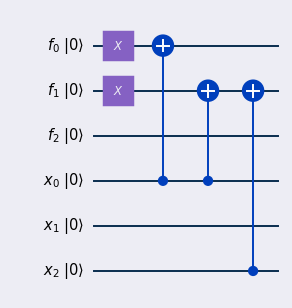

In [36]:
# Generate a secret s n-bitstring periodic function
n = 3
s_secret = format(random.randint(1, 2**n - 1), f'0{n}b')
f = build_periodic_function(s_secret)

# Create a the oracle circuit U_f   
c_Uf_oracle = build_periodic_oracle(f)
print("\nCircuit:")
draw_qibo(c_Uf_oracle,scale=0.7);

<div class="alert alert-block alert-warning">

**Observe**: clicking repeatedly on this cell yields oracles of higher or lower depth (number of gates). Short oracles give more reliable results. 
        
</div>

This circuit implements the operation $U_f\ket{0} \ket{x} \to \ket{f(x)}\ket{x}$. Let us verify it. 

In [37]:
# select x in S_n randomly and show f(x) and x
x = format(random.randint(1,2**n), f'0{n}b')
print('f(x) =', f[x], '; x=',x)


# Prepare state |x> = |000>, |001>, ... in the last n qubits
#c_prep = Circuit(2 * n)
c_prep = Circuit(2 * n, wire_names=[f"f_{i}" for i in range(n)] + [f"x_{i}" for i in range(n)])

for j, bit in enumerate(x):
    if bit == '1':
        c_prep.add(gates.X(n + j))  # x register starts at qubit n

#Concatenate  Uf
c_eval = c_prep +  c_Uf_oracle  

# uncomment to show the circuit
#display(draw_qibo(c_eval));

# Verify: show the state
state = show_state(c_eval)


f(x) = 100 ; x= 001


<IPython.core.display.Latex object>

Check that the output was $\ket{f_0(x)...f_{n-1}(x)\, x_0...x_{n-1}} = \ket{f(x)}\ket{x}$

##  Simon's quantum solution

The Simon's quantum algorithm involves **all the resources** that we have explored previously in this notebook. 

They enter sequentially in **three steps** acting on the initial state $\ket{0}$.
<br>

1. **Superposition**:  <u>span</u> the computational basis by applying $H^n\ket{0}_n \approx \ket{0} + \ket{1} + \ket{2} ... + \ket{2^n-1} = \sum_x \ket{x}$
<br>

2. **Paralelism**: <u>evaluate</u> the oracle $U_f$ <u>*in parallel*</u> on **all** basis elements of the computational basis **simultaneously**.
<br>
$$
U_f \sum_x\ket{0}\ket{x} = \sum_x \ket{f(x)}\ket{x}
$$
<br>
Although we did not explain it, this is a highly <b>entangled</b> state.
<br>
<br>

3. **Interference**: make the $\ket{x}$ states <u>interfere</u> among themselves, by applying $H^n$ again (like in the quantum $n$ coin).
<br>

<br>

*[Diagram of the Simon circuit from the original material: not included]*

### The circuit

let us make up the circuit as a composition of the three layers

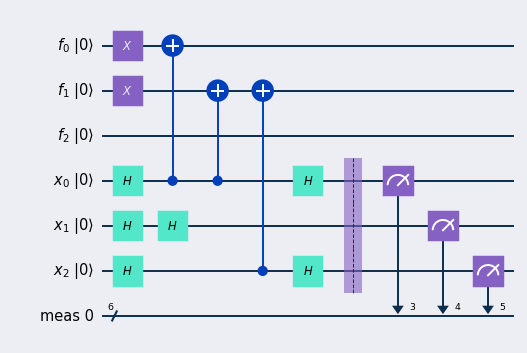

In [38]:
# Walsh-Hadamard layer
c_WH = Circuit(2 * n,wire_names=[f"f_{i}" for i in range(n)] + [f"x_{i}" for i in range(n)])
for i in range(n):
    c_WH.add(gates.H(n+i))
    
# full Simon circuit
c = c_WH + c_Uf_oracle + c_WH

# measure only  |x>
c.add(gates.M(*range(n,2*n)))
draw_qibo(c,scale=0.7);


### Measuring


Like in the quantum coin, the second layer of $H^n$ causes many amplitudes to cancel out by **destructive interference**.  

$\Rightarrow$  before measurments, the resulting state $\ket{\psi}_{out}$ will have <u>a few basis states</u> contributing

$$
\ket{\psi}_{out} = \sum_{y\in Y}  \ket{y}
$$

In Simon's algorithm:

- the secret string $s$ is *not obtained* in a single measurement 
<br>

- <u>each run</u> produces a bitstring $y = y_{n-1}...y_0 $, that **fulfills** the *following equation*

$$
s\cdot y ~=~ s_{n-1}y_{n-1} \oplus s_{n-2}y_{n-2} \oplus \ldots \oplus s_0 y_0  ~=~ 0  
$$


In [41]:
shots = 100
run_hardware = True

counts = run_qmio(circuit_to_qmio(c, assume_second_half_if_missing=True), shots=shots, run_hardware=run_hardware)

Fake QMIO: {'000': 25, '101': 21, '100': 29, '001': 25}
QMIO job_id: 3a0d90df-db30-4e17-871b-66260eed954a
QMIO: {'101': 20, '001': 22, '100': 14, '000': 33, '111': 3, '011': 6, '010': 2}


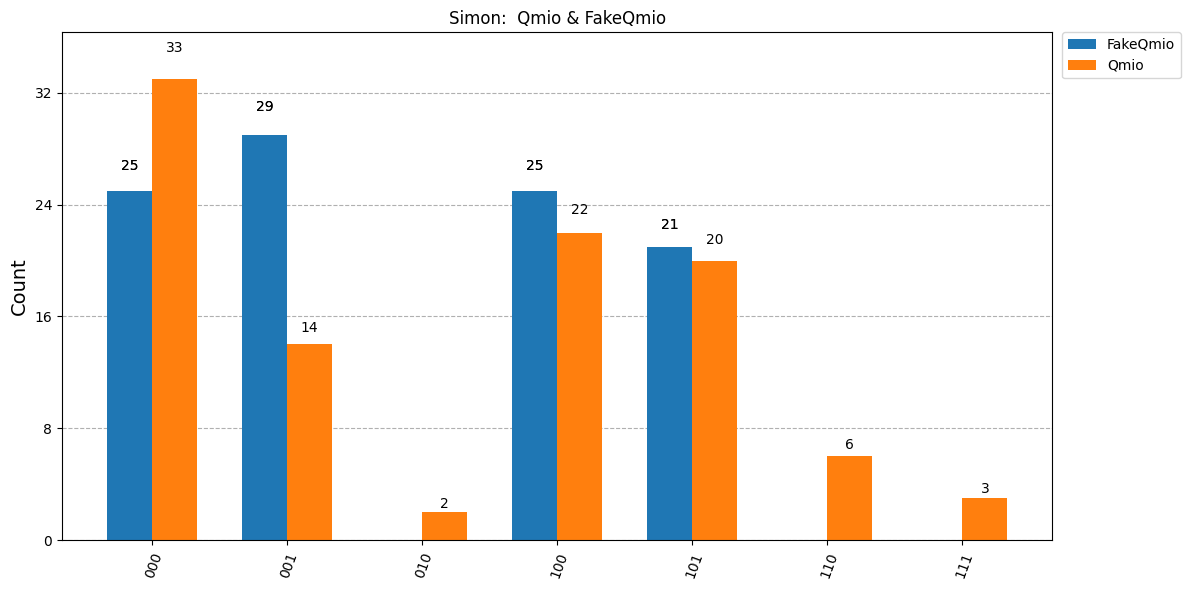

In [42]:
counts_fake_qmio = reverse_bitstrings(counts["fake_qmio"])
counts_qmio = {format(k, f'0{n}b'): 0 for k in range(2**n)}

if run_hardware == True:
    counts_qmio = reverse_bitstrings(counts["qmio"])

plot_histogram(
    [counts_fake_qmio, counts_qmio],
    legend=["FakeQmio", "Qmio"],
    title="Simon:  Qmio & FakeQmio",  figsize=(12,6)
);    
#plot_counts(counts_fake_qmio, figsize=(8, 6), title="Results in FakeQmio")

 If the Qmio results are very bad try with a periodic function that has a shorter oracle circuit.

<div class="alert alert-block alert-success">
<b> Go play!</B>

Skip the last $H^n$  layer  to see the effect of the interference in action.
</div>

## Solving for  $s$


After measuring we  obtain some results $y^1, y^2,...$  all of which satisfy the same equation 

\begin{align}
s\cdot y^1 & = 0 \\
s\cdot y^2 & = 0 \\
\vdots
\end{align}

This is a **linear systems of equations** for $n$ unkowns $s = (s_{n-1},...., s_{0})$. 


<div class="alert alert-block alert-warning">
<b> Notice:</b>   

the probability distribution (histogram) is **peaked** in a few states $\ket{y^{(a)}}$. This is what makes this algorithm advantageous:
    
- running a <u>small number</u> of times **the solution** bitstrings $y^{(a)}$ will <u>promptly</u> show up  and become <u>distinguishable</u>
<br>    
    
- we actually <u>only need</u> to find $n-1$ valid bitstrings to solve the linear system $s\cdot y^{(a)} = 0, \, \, a=1,...,n-1$.     
    
</div>

Let us now find out if we hit the correct periodicity $s$. We make a list with $n$ the most probable bistrings.

From simulating with **FakeQmio**

In [43]:
top_fake_qmio = most_probable_bitstrings(counts_fake_qmio,n)
print('from FakeQmio -> most probable y^a =', top_fake_qmio)
solve_for_solution(top_fake_qmio)

from FakeQmio -> most probable y^a = {'001': 29, '100': 25, '101': 21}
solution for s = 010


From real evaluation on **Qmio**

In [44]:
if run_hardware:
    top_qmio = most_probable_bitstrings(counts_qmio,n)
    print('from Qmio -> most probable y^a =', top_qmio)
    solve_for_solution(top_qmio)
else:
    print('Qmio not operative')
    

from Qmio -> most probable y^a = {'100': 22, '101': 20, '001': 14}
solution for s = 010


<div class="alert alert-block alert-danger">

**At last!** 
    
we can <u> unveil the secret periodicity</u> $s$ to see if we succeeded in finding it  !!!!
</div>

<img src="https://media0.giphy.com/media/v1.Y2lkPTc5MGI3NjExZTZyeDU5ZXh3NGR0NGVodXlkaTZ6bjRmeHNhcHh4MTc0enBoNm9mNyZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/pDdzX4l9jqA80/giphy.gif" width="300">


In [45]:
print('s_secret =', s_secret)

s_secret = 010


<div class="alert alert-block alert-success">

<b> Go  play!</b>

-  If **Qmio** did not give a solution for $n=3$ <u>try with a shorter oracle</u>.
    
    
    
-  Experience the <b>power</b> of the Simon's algorithm by running on FakeQmio (set False)  with higher values of $n=7,...$
    
   
    
</div>






##  Congratulations!  OBJECTIVE REACHED!

<img src="https://media.giphy.com/media/JkQW0NsfGJYWI/giphy.gif" width="300">


### In this session you learned:

- How quantum states are created and measured
- How circuits circuits use parallelism, interference and entanglemente to perform algorithms. 
- How combining these resources can give exponential speedup over classical solutions.
- The difference between ideal and real quantum computers. 



<img src="https://media.giphy.com/media/3o7btPCcdNniyf0ArS/giphy.gif" width="300">

<u>Key takeaway:</u>
Quantum computers are **potentially** powerful, but **noise** is still a major challenge.

